In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import json
import os
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

In [2]:
reddit_datasets = {
    'addiction': pd.read_csv('addiction_2019_features_tfidf_256.csv'),
    'adhd': pd.read_csv('adhd_2019_features_tfidf_256.csv'),
    'alcoholism': pd.read_csv('alcoholism_2019_features_tfidf_256.csv'),
    'anxiety': pd.read_csv('anxiety_2019_features_tfidf_256.csv'),
    'jokes': pd.read_csv('jokes_2019_features_tfidf_256.csv'),
    'mentalhealth': pd.read_csv('mentalhealth_2019_features_tfidf_256.csv'),
    'conspiracy': pd.read_csv('conspiracy_2019_features_tfidf_256.csv'),
    'fitness': pd.read_csv('fitness_2019_features_tfidf_256.csv'),
    'meditation': pd.read_csv('meditation_2019_features_tfidf_256.csv'),
    'relationship': pd.read_csv('relationships_2019_features_tfidf_256.csv'),
    'teaching': pd.read_csv('teaching_2019_features_tfidf_256.csv'),
    'suicidewatch': pd.read_csv('suicidewatch_2019_features_tfidf_256.csv'),
}

for name, df in reddit_datasets.items():
    df['subreddit_name'] = name

combined_df = pd.concat(reddit_datasets.values(), ignore_index=True)


In [3]:
print(combined_df.columns)


Index(['subreddit', 'author', 'date', 'post', 'automated_readability_index',
       'coleman_liau_index', 'flesch_kincaid_grade_level',
       'flesch_reading_ease', 'gulpease_index', 'gunning_fog_index',
       ...
       'tfidf_without', 'tfidf_wonder', 'tfidf_work', 'tfidf_worri',
       'tfidf_wors', 'tfidf_would', 'tfidf_wrong', 'tfidf_x200b', 'tfidf_year',
       'subreddit_name'],
      dtype='object', length=351)


In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import joblib
import pandas as pd

# 1️⃣ Prepare Reddit labels
depressive_subs = ['suicidewatch', 'mentalhealth', 'anxiety', 'addiction', 'alcoholism']
combined_df['label'] = combined_df['subreddit_name'].apply(lambda x: 1 if x in depressive_subs else 0)

# 2️⃣ Fit a TF-IDF vectorizer on Reddit text
reddit_texts = combined_df['post'].astype(str)
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
X = vectorizer.fit_transform(reddit_texts)
y = combined_df['label']

# 3️⃣ Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4️⃣ Train SVM
svm = LinearSVC(C=1.0, class_weight='balanced', max_iter=5000)
svm.fit(X_train, y_train)

# 5️⃣ Evaluate on Reddit test set
y_pred = svm.predict(X_test)
print("✅ Reddit Accuracy:", accuracy_score(y_test, y_pred))
print("\n📊 Reddit Classification Report:\n", classification_report(y_test, y_pred))

# 6️⃣ Save model and vectorizer for later Twitter predictions
joblib.dump(svm, "svm_reddit_tfidf.pkl")
joblib.dump(vectorizer, "tfidf_reddit_vectorizer.pkl")


✅ Reddit Accuracy: 0.9341476154124312

📊 Reddit Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.94      0.95     16982
           1       0.88      0.92      0.90      7907

    accuracy                           0.93     24889
   macro avg       0.92      0.93      0.93     24889
weighted avg       0.94      0.93      0.93     24889



['tfidf_reddit_vectorizer.pkl']

In [37]:
import joblib

# After training your model and vectorizer
joblib.dump(svm, "svm_reddit_tfidf.pkl")          # save trained SVM
joblib.dump(vectorizer, "tfidf_reddit_vectorizer.pkl")  # save TF-IDF vectorizer


['tfidf_reddit_vectorizer.pkl']

In [38]:
twitter_df = pd.read_csv("Mental-Health-Twitter.csv")
print(twitter_df.columns)


Index(['Unnamed: 0', 'post_id', 'post_created', 'post_text', 'user_id',
       'followers', 'friends', 'favourites', 'statuses', 'retweets', 'label'],
      dtype='object')


✅ Twitter Accuracy: 0.5718

📊 Twitter Classification Report:
               precision    recall  f1-score   support

           0       0.54      0.90      0.68     10000
           1       0.70      0.25      0.37     10000

    accuracy                           0.57     20000
   macro avg       0.62      0.57      0.52     20000
weighted avg       0.62      0.57      0.52     20000



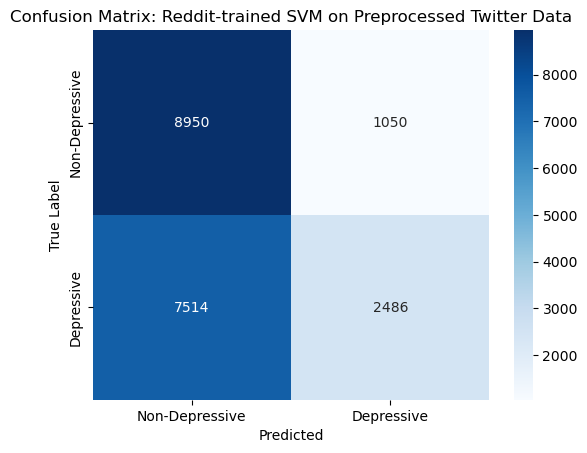

In [39]:
import pandas as pd
import joblib
import re
import string
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


# Load trained Reddit SVM and TF-IDF vectorizer

svm = joblib.load("svm_reddit_tfidf.pkl")
vectorizer = joblib.load("tfidf_reddit_vectorizer.pkl")


# Load Twitter dataset

twitter_df = pd.read_csv("Mental-Health-Twitter.csv")


# Preprocess Twitter text

def preprocess_tweet(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)      # remove URLs
    text = re.sub(r"@\w+", "", text)                # remove mentions
    text = re.sub(r"#(\w+)", r"\1", text)           # remove # but keep word
    text = re.sub(r"[^\w\s,]", "", text)            # remove emojis/symbols/punctuation
    text = re.sub(r'\d+', '', text)                 # remove numbers
    text = re.sub(r'\s+', ' ', text).strip()        # normalize spaces
    return text

twitter_df["clean_text"] = twitter_df["post_text"].astype(str).apply(preprocess_tweet)


# Transform Twitter text using Reddit TF-IDF vectorizer

X_twitter = vectorizer.transform(twitter_df["clean_text"])
y_twitter = twitter_df["label"]


# Predict using Reddit-trained SVM

predicted_depression = svm.predict(X_twitter)


# Evaluate performance

print("✅ Twitter Accuracy:", accuracy_score(y_twitter, predicted_depression))
print("\n📊 Twitter Classification Report:\n", classification_report(y_twitter, predicted_depression, zero_division=0))

# ------------------------------
# Visualize confusion matrix
# ------------------------------
cm = confusion_matrix(y_twitter, predicted_depression)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Non-Depressive", "Depressive"],
            yticklabels=["Non-Depressive", "Depressive"])
plt.xlabel("Predicted")
plt.ylabel("True Label")
plt.title("Confusion Matrix: Reddit-trained SVM on Preprocessed Twitter Data")
plt.show()


Twitter Accuracy: 0.5

Classification Report:
               precision    recall  f1-score   support

           0       0.50      1.00      0.67     10000
           1       0.00      0.00      0.00     10000

    accuracy                           0.50     20000
   macro avg       0.25      0.50      0.33     20000
weighted avg       0.25      0.50      0.33     20000



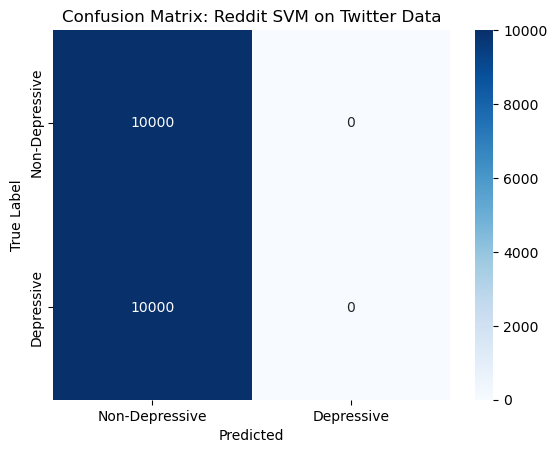

In [40]:
import pandas as pd
import joblib
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# --- Load trained Reddit SVM and TF-IDF vectorizer ---
svm = joblib.load("svm_reddit_tfidf.pkl")
vectorizer = joblib.load("tfidf_reddit_vectorizer.pkl")  # if you saved it earlier

# --- Load Twitter dataset ---
twitter_df = pd.read_csv("Mental-Health-Twitter.csv")

# --- Prepare features and labels ---
X_twitter = vectorizer.transform(twitter_df['post_text'].astype(str))
y_twitter = twitter_df['label']

# --- Predict using Reddit-trained SVM ---
twitter_preds = svm.predict(X_twitter)

# --- Map Reddit subreddit predictions to Depressive / Non-Depressive ---
depressive_subs = ["suicidewatch", "anxiety", "depression", "mentalhealth", "addiction", "alcoholism"]
predicted_depression = [1 if p in depressive_subs else 0 for p in twitter_preds]

# --- Evaluate performance ---
print("Twitter Accuracy:", accuracy_score(y_twitter, predicted_depression))
print("\nClassification Report:\n", classification_report(y_twitter, predicted_depression, zero_division=0))

# --- Confusion matrix ---
cm = confusion_matrix(y_twitter, predicted_depression)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Non-Depressive","Depressive"],
            yticklabels=["Non-Depressive","Depressive"])
plt.xlabel("Predicted")
plt.ylabel("True Label")
plt.title("Confusion Matrix: Reddit SVM on Twitter Data")
plt.show()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\minht\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\minht\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


✅ Twitter Accuracy: 0.57245

📊 Twitter Classification Report:
               precision    recall  f1-score   support

           0       0.55      0.84      0.66     10000
           1       0.66      0.30      0.42     10000

    accuracy                           0.57     20000
   macro avg       0.60      0.57      0.54     20000
weighted avg       0.60      0.57      0.54     20000



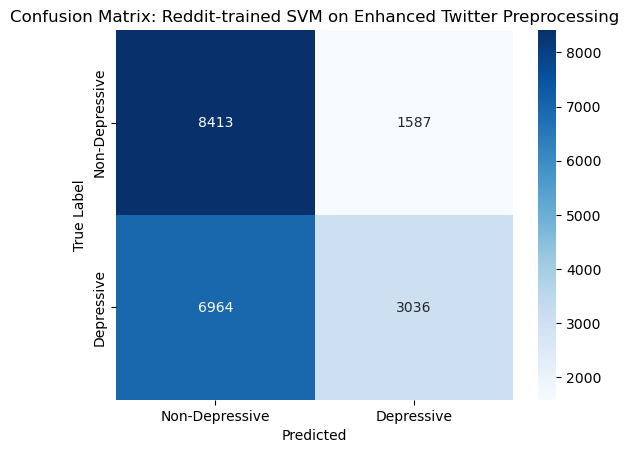

In [41]:
import pandas as pd
import joblib
import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


# Setup and load model/vectorizer

nltk.download('stopwords')
nltk.download('wordnet')

svm = joblib.load("svm_reddit_tfidf.pkl")
vectorizer = joblib.load("tfidf_reddit_vectorizer.pkl")


# Load Twitter dataset

twitter_df = pd.read_csv("Mental-Health-Twitter.csv")


# Preprocessing pipeline

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_tweet(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)      # remove URLs
    text = re.sub(r"@\w+", "", text)                # remove mentions
    text = re.sub(r"#(\w+)", r"\1", text)           # remove # but keep word
    text = re.sub(r"[^a-z\s]", "", text)            # remove punctuation, numbers, symbols
    text = re.sub(r'\s+', ' ', text).strip()        # normalize spaces
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)

twitter_df["clean_text"] = twitter_df["post_text"].astype(str).apply(preprocess_tweet)


# Transform Twitter text using Reddit TF-IDF vectorizer

X_twitter = vectorizer.transform(twitter_df["clean_text"])
y_twitter = twitter_df["label"]


# Predict using Reddit-trained SVM

predicted_depression = svm.predict(X_twitter)


# Evaluate performance

print("✅ Twitter Accuracy:", accuracy_score(y_twitter, predicted_depression))
print("\n📊 Twitter Classification Report:\n",
      classification_report(y_twitter, predicted_depression, zero_division=0))


# Visualize confusion matrix

cm = confusion_matrix(y_twitter, predicted_depression)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Non-Depressive", "Depressive"],
            yticklabels=["Non-Depressive", "Depressive"])
plt.xlabel("Predicted")
plt.ylabel("True Label")
plt.title("Confusion Matrix: Reddit-trained SVM on Enhanced Twitter Preprocessing")
plt.show()

# ------------------------------
# Suggested improvements:

#  - Re-train Reddit SVM using bi-grams/trigrams and sublinear_tf=True in TF-IDF:
#    vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1,3), sublinear_tf=True)
#  - Apply GridSearchCV to find best ‘C’ for SVM
#  - Try LogisticRegression, SGDClassifier, or fine-tuned BERT baseline for comparison
